# 09 粉塵沈着とフィルター

換気に加え、沈着と循環清浄機による除去を組み込む。

## 到達目標
beta[1/s]、eta[0..1]。粒径別に与える場合は粒径ごとに別計算し、数濃度と質量濃度を混同しない。

## 実行環境
Python 3.10以上とvtsimnx engineが必要です。Colabのlocalhostは手元PCのサーバーを指しません。次の設定セルのAPI URLを到達可能なものに変更します。APIキーは環境変数で渡し、ノートに保存しません。

検証engine commit: `5eeffb2f8012a2fe41bca705450b0dd0a952326d`。入力モデルは実計算確認済ですが、原住宅の年間再現とは範囲が異なります。

## 実行版の使い方
このノートは検証対象のvtsimnx commit 5eeffb2f8012a2fe41bca705450b0dd0a952326d に合わせた代表教材です。上から順に実行します。
Pythonクライアントの導入だけではengineは起動しません。教材17以外は接続可能なengineと、必要に応じてVTSIMNX_API_KEYが必要です。Colabの127.0.0.1は手元PCのengineを指しません。
入力はノート内に含めています。元のDriveパスや測定CSVを別途読む必要はありません。
出力は教材フォルダ内のresults/09/に保存します。詳しい準備は同じフォルダの00_実行ガイド.ipynbを参照してください。


In [1]:
import os, sys, subprocess
# 検証runnerのみ専用環境で導入済みの依存を再利用する。通常はこのセルで導入する。
if os.environ.get("VTSIMNX_TUTORIAL_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools>=68,<81", "wheel"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "vtsimnx @ git+https://github.com/iguchi-lab/vtsimnx@5eeffb2f8012a2fe41bca705450b0dd0a952326d",
        "matplotlib", "japanize-matplotlib"])


In [2]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from IPython.display import display
import vtsimnx as vt

# ローカルJupyterでは、ノートブックと同じフォルダを作業フォルダにする。
DATA_DIR = Path(os.environ.get("VTSIMNX_TUTORIAL_DATA", ".")).expanduser().resolve()
BASE_URL = os.environ.get("VTSIMNX_API_URL", "http://127.0.0.1:8000")
API_KEY = os.environ.get("VTSIMNX_API_KEY")
OUTPUT = DATA_DIR / "results" / "09"
OUTPUT.mkdir(parents=True, exist_ok=True)


## 入力を読む
次の辞書はvtsimnxのネイティブ形式です。風量はm³/s、熱量はW、熱容量はJ/Kです。

In [3]:
configs = {'09_particles': {'builder': {},
                  'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                           'end': '2026-01-01T00:59:00',
                                           'length': 60,
                                           'timestep': 60}},
                  'nodes': [{'key': 'outside', 't': 20, 'c': 0},
                            {'key': 'room', 't': 20, 'c': 1000, 'calc_c': True, 'v': 50, 'beta': 0.0001},
                            {'key': 'cleaner', 't': 20, 'c': 0, 'calc_c': True, 'v': 0}],
                  'ventilation_branches': [{'key': 'outside->room',
                                            'source': 'outside',
                                            'target': 'room',
                                            'vol': 0.013888888888888888},
                                           {'key': 'room->outside',
                                            'source': 'room',
                                            'target': 'outside',
                                            'vol': 0.013888888888888888},
                                           {'key': 'room->cleaner',
                                            'source': 'room',
                                            'target': 'cleaner',
                                            'vol': 0.027777777777777776,
                                            'eta': 0.8},
                                           {'key': 'cleaner->room',
                                            'source': 'cleaner',
                                            'target': 'room',
                                            'vol': 0.027777777777777776}],
                  'thermal_branches': []}}


## 実行と結果の取得
計算ごとの要求JSONを保存し、必要な系列をDataFrameとして取得します。

In [4]:
results = {}
for name, config in configs.items():
    results[name] = vt.run_calc(BASE_URL, config, api_key=API_KEY,
        as_result=True, raise_on_error=True, timeout=1800, request_output_path=OUTPUT / (name + "_request.json"))
    print(name, results[name].artifact_dir)


09_particles artifacts.1794699410200.output.765c3901b48242368a1524f0ed8b55fd


09_particles


,cleaner,room
time,,
2026-01-01 00:00:00,190.597198,952.986023
2026-01-01 00:01:00,181.636475,908.182373
2026-01-01 00:02:00,173.097015,865.485107
2026-01-01 00:03:00,164.959045,824.795227
2026-01-01 00:04:00,157.203659,786.018311


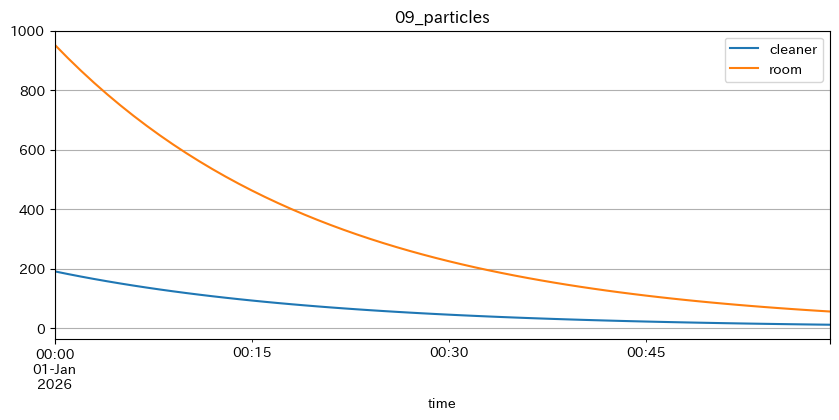

In [5]:
frames = {name: result.get_series_df('concentration_c', raise_on_error=True) for name, result in results.items()}
for name, frame in frames.items():
    print(name)
    display(frame.head())
    frame.to_csv(OUTPUT / (name + "_concentration_c.csv"), encoding="utf-8-sig")
    frame.plot(title=name, figsize=(10, 4), grid=True)


## 確認・発展
eta=0、beta=0の条件と比較して、除去要因を分離する。

保存された時刻の値は当該ステップ更新後の値です。初期値との比較ではこの差に注意します。

## 原典との対応
- S238 231211_枚方_vtsim_北大送付.ipynb
- S240 231217_PMsim  のコピー
- S241 231228_PMsim のコピー
- S242 240105_PMsim のコピー のコピー
- S243 浦和中間粒径シミュレーション  のコピー のコピー
- S244 道東ハウス_シミュレーション
- S245 shase2022_1_1.ipynb
- S249 210829_清浄度sim.ipynb
- S250 220302_浦和粉塵.ipynb
- S252 230814_モデルフィッティング.ipynb
- S253 モデルフィッティング.ipynb
- S254 モデルフィッティング2.ipynb

S番号は原典調査時の識別子です。原典の完全な台帳は管理者のDrive整理資料に保管しています。